## Step 1: Import libraries
Import TensorFlow, Keras, and the required neural-network layers.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2: Load the dataset
Load the CIFAR-10 dataset. To keep this practical lightweight, use the first 2,000 training images and first 500 test images, as specified in the source document.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train[:2000]
y_train = y_train[:2000]

x_test = x_test[:500]
y_test = y_test[:500]

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1930s 11us/step
Training images shape: (2000, 32, 32, 3)
Training labels shape: (2000, 1)
Testing images shape: (500, 32, 32, 3)
Testing labels shape: (500, 1)


### View a few dataset images
CIFAR-10 contains 32 × 32 colour images from 10 classes. Display a few examples to inspect the data.

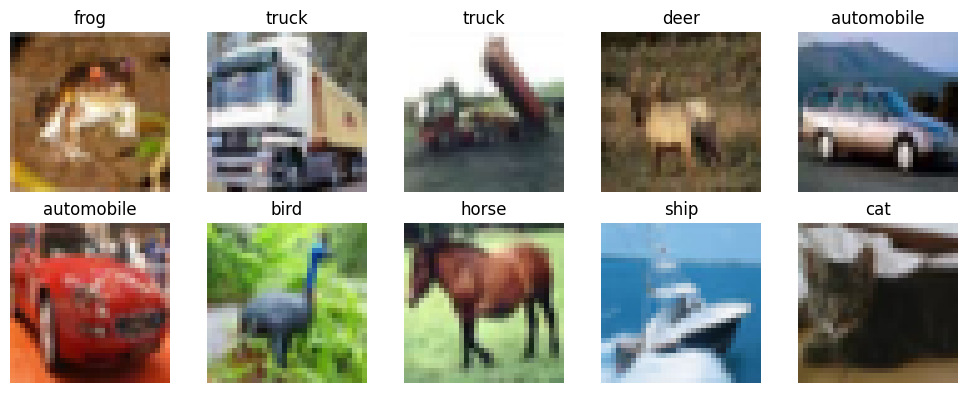

In [3]:
import matplotlib.pyplot as plt

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 3: Load a pre-trained CNN model
Load MobileNetV2 with ImageNet weights. `include_top=False` removes its original classification head so that a new classifier can be added.

In [4]:
base_model = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(32, 32, 3)
)

print("Pre-trained MobileNetV2 loaded.")

/tmp/ipykernel_4917/3955296074.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Pre-trained MobileNetV2 loaded.


**Explanation**
- `weights="imagenet"` loads weights learned from the ImageNet dataset.
- `include_top=False` excludes the original final classification layers.
- `input_shape=(32, 32, 3)` matches the CIFAR-10 image dimensions.

## Step 4: Freeze the pre-trained layers
Freeze the base model so its learned weights remain unchanged while the new classifier is trained.

In [5]:
base_model.trainable = False

print("Base model trainable:", base_model.trainable)

Base model trainable: False


## Step 5: Add a custom classifier
Build a model that rescales input pixels, extracts features using MobileNetV2, averages the feature maps, and predicts one of the 10 CIFAR-10 classes.

In [6]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1, 1, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Explanation**
- **Rescaling:** Maps pixel values from the 0–255 range to approximately -1 to 1, as expected by MobileNetV2.
- **MobileNetV2:** Extracts image features using its pre-trained convolutional layers.
- **GlobalAveragePooling2D:** Reduces each feature map to a single value.
- **Dense (128, ReLU):** Learns task-specific features.
- **Dense (10, softmax):** Produces probabilities for the 10 CIFAR-10 classes.

## Step 6: Compile the model
Configure the optimizer, loss function, and evaluation metric.

In [7]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


## Step 7: Train the model
Train the custom classifier for 2 epochs, using 20% of the training subset for validation, as specified in the practical.

In [8]:
history = model.fit(
    x_train,
    y_train,
    epochs=2,
    validation_split=0.2
)

Epoch 1/2
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.1581 - loss: 2.2573 - val_accuracy: 0.2350 - val_loss: 2.1900
Epoch 2/2
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.2575 - loss: 2.1494 - val_accuracy: 0.2525 - val_loss: 2.1151


### Plot training and validation accuracy
Visualize the accuracy recorded during the initial training phase.

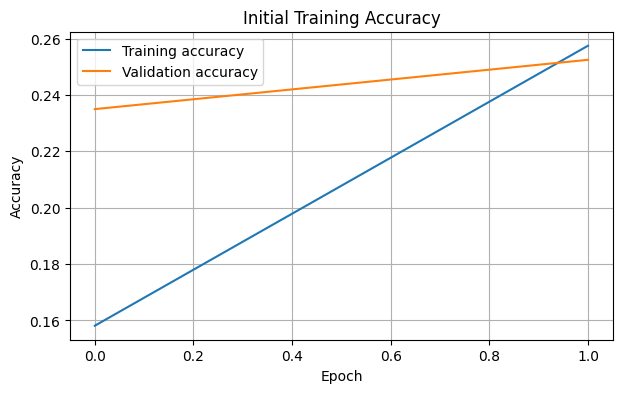

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Initial Training Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## Step 8: Evaluate the model
Evaluate the trained model on the 500 test images and print the test accuracy.

In [10]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)

print("Test Accuracy:", accuracy * 100, "%")
print("Test Loss:", loss)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.2280 - loss: 2.1361
Test Accuracy: 22.80000001192093 %
Test Loss: 2.1361119747161865


## Step 9: Fine-tune the model
Unfreeze the base model, then freeze all but its last 20 layers. Recompile with a very small learning rate and train for one additional epoch, following the supplied practical.

In [11]:
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

print("Total base-model layers:", len(base_model.layers))
print("Trainable base-model layers:", sum(layer.trainable for layer in base_model.layers))

Total base-model layers: 154
Trainable base-model layers: 20


### Recompile with a lower learning rate
A small learning rate helps make gradual adjustments to the selected pre-trained layers.

In [12]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


### Train the fine-tuned model
Perform one additional epoch of training, as specified in the practical.

In [13]:
fine_tune_history = model.fit(
    x_train,
    y_train,
    epochs=1
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 83ms/step - accuracy: 0.1370 - loss: 3.3438


## Final evaluation
Evaluate the fine-tuned model on the test subset to observe its performance after fine-tuning.

In [14]:
fine_tune_loss, fine_tune_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Fine-tuned Test Accuracy:", fine_tune_accuracy * 100, "%")
print("Fine-tuned Test Loss:", fine_tune_loss)

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.2140 - loss: 2.1847
Fine-tuned Test Accuracy: 21.400000154972076 %
Fine-tuned Test Loss: 2.184722423553467


## Display sample predictions
Show a few test images with their predicted CIFAR-10 class labels.

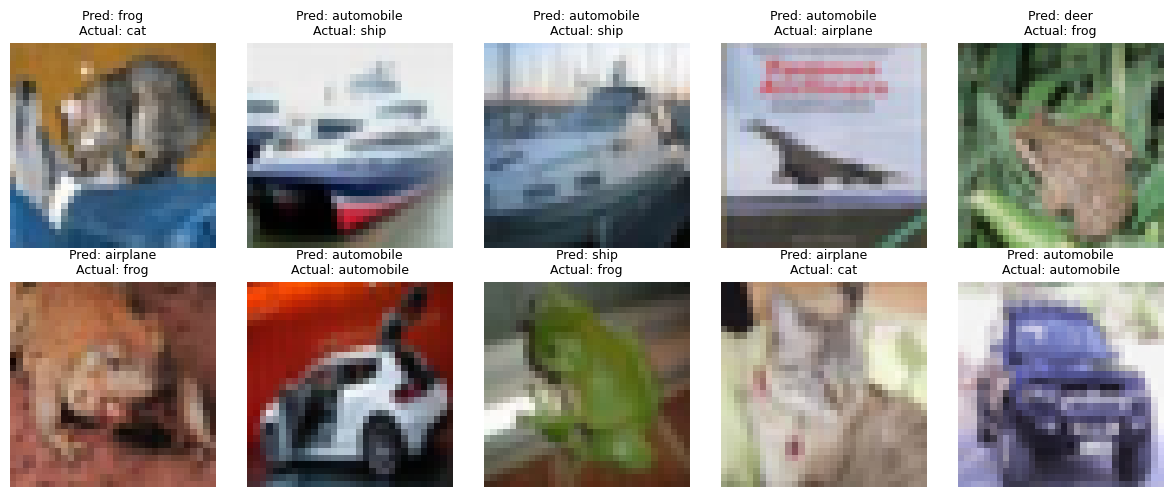

In [15]:
predictions = model.predict(x_test[:10], verbose=0)
predicted_classes = tf.argmax(predictions, axis=1).numpy()

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    actual = class_names[int(y_test[i][0])]
    predicted = class_names[int(predicted_classes[i])]
    plt.title(f"Pred: {predicted}\nActual: {actual}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Result

The transfer-learning workflow was implemented using a pre-trained MobileNetV2 CNN architecture and the CIFAR-10 dataset. The pre-trained base layers were initially frozen, a custom 10-class classifier was trained, the model was evaluated, and selected deeper layers were fine-tuned using a lower learning rate.

**Important:** This supplied practical's implementation predicts one class for each image. It demonstrates transfer learning for image classification; it does not generate object bounding boxes or detect multiple object locations.

---

## Viva-Voce Questions and Answers

1. **What is transfer learning?**  
   Transfer learning reuses knowledge learned by a model on one task or dataset to solve a different but related task.

2. **What is a CNN?**  
   A Convolutional Neural Network is a deep-learning model commonly used to process images.

3. **What is the aim of this practical?**  
   To use a pre-trained CNN model to recognize image classes through transfer learning.

4. **What is MobileNetV2?**  
   MobileNetV2 is an efficient CNN architecture designed for image recognition, including use on resource-constrained devices.

5. **What is ImageNet?**  
   ImageNet is a large image dataset commonly used to train and evaluate image-recognition models.

6. **What does `weights="imagenet"` mean?**  
   It loads model weights previously learned from the ImageNet dataset.

7. **What does `include_top=False` do?**  
   It removes the original final classification head of the pre-trained network.

8. **What is a pre-trained model?**  
   It is a model whose weights have already been learned from an earlier training task.

9. **Why use a pre-trained model?**  
   It can reduce training time and reuse useful visual features learned from a large dataset.

10. **What is CIFAR-10?**  
    CIFAR-10 is an image dataset containing 60,000 colour images across 10 classes, with each image sized 32 × 32 pixels.

11. **Name the 10 CIFAR-10 classes.**  
    Airplane, automobile, bird, cat, deer, dog, frog, horse, ship, and truck.

12. **Why does this practical use only 2,000 training images and 500 test images?**  
    The source practical selects smaller subsets to keep the demonstration lightweight.

13. **What does freezing layers mean?**  
    It means keeping their weights unchanged during training.

14. **Why freeze the pre-trained base model initially?**  
    To preserve its learned features while training only the newly added classifier layers.

15. **What is a custom classifier?**  
    It is a set of newly added layers designed to predict classes for the new task.

16. **What does the Rescaling layer do?**  
    It transforms pixel values from 0–255 to approximately -1 to 1.

17. **Why is input rescaling important for MobileNetV2?**  
    It makes the input range compatible with the preprocessing expected by the pre-trained model.

18. **What is GlobalAveragePooling2D?**  
    It averages each feature map spatially to produce a compact feature vector.

19. **Why is ReLU used?**  
    ReLU introduces non-linearity and outputs zero for negative input values while retaining positive values.

20. **Why is softmax used in the final layer?**  
    It converts output scores into probabilities across the 10 classes.

21. **Why does the final Dense layer have 10 neurons?**  
    Because CIFAR-10 contains 10 classes.

22. **What is an epoch?**  
    One complete pass through the training dataset.

23. **What is the Adam optimizer?**  
    Adam is an optimization algorithm that adaptively updates model weights during training.

24. **What is sparse categorical crossentropy?**  
    It is a loss function used for multi-class classification when labels are provided as integer class IDs.

25. **What is accuracy?**  
    Accuracy is the fraction of predictions that correctly match the true labels.

26. **What is validation data?**  
    It is data held out from weight updates and used to monitor model performance during training.

27. **What does `validation_split=0.2` mean?**  
    It reserves 20% of the supplied training data for validation.

28. **What is fine-tuning?**  
    Fine-tuning means unfreezing some pre-trained layers and training them further on the new dataset.

29. **Why use a low learning rate during fine-tuning?**  
    To make small weight updates and reduce the risk of damaging useful pre-trained features.

30. **What does `base_model.layers[:-20]` select?**  
    It selects all base-model layers except the last 20, which are left trainable by the loop.

31. **What is the difference between feature extraction and fine-tuning?**  
    Feature extraction keeps the pre-trained base frozen; fine-tuning updates selected pre-trained layers on the new data.

32. **What is overfitting?**  
    Overfitting occurs when a model learns the training data too closely and performs poorly on unseen data.

33. **What is underfitting?**  
    Underfitting occurs when a model has not learned the patterns in the data sufficiently.

34. **What are common applications of transfer learning?**  
    Image classification, medical image analysis, object recognition, and other tasks with limited labelled data.

35. **Is the supplied implementation full object detection?**  
    No. It predicts one class for each image. Full object detection also identifies object locations, usually using bounding boxes.

36. **What is the difference between image classification and object detection?**  
    Image classification assigns a label to an image; object detection identifies objects and their locations within an image.

37. **What is a bounding box?**  
    A rectangular region around an object in an image, commonly represented by coordinates.

38. **Does this practical produce bounding boxes?**  
    No. Its model has a 10-class softmax output and does not predict bounding-box coordinates.

39. **Why can transfer learning be useful when the dataset is small?**  
    The model can reuse general visual features learned from a larger dataset rather than learning all features from scratch.

40. **What is the role of `model.evaluate()`?**  
    It calculates the model's loss and configured metrics on the supplied evaluation data.

---

## Important Parameters

| Parameter | Value | Purpose |
|---|---:|---|
| Dataset | CIFAR-10 | Image classification dataset |
| Training subset | 2,000 images | Training data |
| Test subset | 500 images | Evaluation data |
| Input shape | 32 × 32 × 3 | Image dimensions |
| Pre-trained model | MobileNetV2 | Feature extraction |
| Pre-trained weights | ImageNet | Previously learned weights |
| Initial training | 2 epochs | Train custom classifier |
| Validation split | 0.2 | 20% validation data |
| Hidden Dense layer | 128 neurons | Custom feature learning |
| Output layer | 10 neurons | CIFAR-10 classes |
| Fine-tuning | Last 20 base layers | Selected layers trainable |
| Fine-tuning learning rate | 0.00001 | Small weight updates |
| Fine-tuning epochs | 1 | Additional training pass |